In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import hashlib, json, shutil, zipfile, platform, warnings, html
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from scipy.signal import butter, sosfiltfilt
from scipy.stats import spearmanr
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/obp_utils.py').exists()), Path.cwd())
RAW, OUT, FIG = [ROOT/p for p in ('data/raw/hitting','results/separation_bat_speed','figures/separation_bat_speed')]
for p in (RAW, OUT, FIG):
    p.mkdir(parents=True, exist_ok=True)
AUTO_DOWNLOAD = True
SELECTED_SWING = None
SEEDS = (20261026, 20261027)
ALPHAS = (.1, 1., 10., 100., 1000.)
BOOTSTRAPS = 2000
GROUP = ['user','session','hitter_side']
EVENTS = ['fp_10_time','fp_100_time','contact_time']
ANGLE_COLS = ['pelvis_angle_z','torso_angle_z','torso_pelvis_angle_z']
RATE_COLS = ['pelvis_angular_velocity_z','torso_angular_velocity_z']
TARGETS = {'peak_speed':'bat_speed_mph_max_x','contact_speed':'bat_speed_mph_contact_x','blast_speed':'blast_bat_speed_mph_x'}
CONTROLS = ['height_m','mass_kg','bat_weight_oz','bat_length_in','left_handed']
MAGNITUDE = ['max_separation_deg','plant_separation_deg']
TIMING = ['peak_separation_ms_before_contact','onset_lag_ms','velocity_peak_lag_ms']
FEATURES = MAGNITUDE + TIMING
PEAKS = ['pelvis_peak_dps','torso_peak_dps']
plt.style.use('seaborn-v0_8-whitegrid')
print('Study 20 | Pelvis–Torso Separation Magnitude, Timing & Bat Speed')
print('Primary separation: pelvis axial angle minus torso axial angle; positive means pelvis leads.')
print('This axial-angle difference is a proxy, not identical to the published relative torso–pelvis rotation.')
print('Primary outcome: published maximum resultant bat speed; its exact peak-search interval is not established here.')
print('Contact and Blast speed are separate outcomes. All findings are observational.')

Study 20 | Pelvis–Torso Separation Magnitude, Timing & Bat Speed
Primary separation: pelvis axial angle minus torso axial angle; positive means pelvis leads.
This axial-angle difference is a proxy, not identical to the published relative torso–pelvis rotation.
Primary outcome: published maximum resultant bat speed; its exact peak-search interval is not established here.
Contact and Blast speed are separate outcomes. All findings are observational.


In [2]:
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

def download(url, path):
    if not AUTO_DOWNLOAD:
        raise FileNotFoundError(str(path))
    print('Downloading', path.name, flush=True)
    tmp = path.with_suffix(path.suffix+'.part')
    urlretrieve(url, tmp)
    tmp.replace(path)

ARCHIVES = {'joint_angles':'98a405c5c4a27c1a599d3e30b39a3087180cc4d4bb69faf62204a1c06881be95',
            'joint_velos':'3822dbce30988bc554ee533e5ccc12a5a3e92a53e185fdcb1cc8ad218dd464e4'}
BASE = 'https://github.com/drivelineresearch/openbiomechanics/releases/download/dataset-v1/'
CSV_BASE = 'https://raw.githubusercontent.com/drivelineresearch/openbiomechanics/dataset-v1/baseball_hitting/data/'
for name, digest in ARCHIVES.items():
    target = RAW/(name+'.csv')
    if not target.exists():
        archive = RAW/('hitting_'+name+'.zip')
        if not archive.exists():
            download(BASE+archive.name, archive)
        if sha256(archive) != digest:
            raise ValueError('Archive checksum mismatch: '+name)
        with zipfile.ZipFile(archive) as z:
            members = [n for n in z.namelist() if Path(n).name == target.name]
            if len(members) != 1:
                raise ValueError('Ambiguous archive: '+name)
            with z.open(members[0]) as src, target.with_suffix('.part').open('wb') as dst:
                shutil.copyfileobj(src,dst)
        target.with_suffix('.part').replace(target)
for name, remote in [('metadata','metadata.csv'),('poi_metrics','poi/poi_metrics.csv')]:
    if not (RAW/(name+'.csv')).exists():
        download(CSV_BASE+remote, RAW/(name+'.csv'))

def keys_ok(df, keys, name):
    if df[keys].isna().any().any() or df.duplicated(keys).any():
        raise ValueError('Missing/duplicate keys: '+name)

angles = pd.read_csv(RAW/'joint_angles.csv', usecols=['session_swing','time']+EVENTS+ANGLE_COLS, dtype={'session_swing':str})
velos = pd.read_csv(RAW/'joint_velos.csv', usecols=['session_swing','time']+EVENTS+RATE_COLS, dtype={'session_swing':str})
metadata = pd.read_csv(RAW/'metadata.csv', dtype={'session_swing':str,'user':str,'session':str})
poi = pd.read_csv(RAW/'poi_metrics.csv', dtype={'session_swing':str})
for name, df, keys in [('metadata',metadata,['session_swing']),('POI',poi,['session_swing']),('angles',angles,['session_swing','time']),('velos',velos,['session_swing','time'])]:
    keys_ok(df,keys,name)
if metadata[GROUP].isna().any().any() or not metadata.hitter_side.isin(['L','R']).all():
    raise ValueError('Invalid hitter identity or batting side')
base = metadata[['session_swing']+GROUP+['session_height_in','session_mass_lbs','bat_weight_oz','bat_length_in']].merge(
    poi[['session_swing']+list(TARGETS.values())+['x_factor_fp_z']], on='session_swing', how='left', validate='one_to_one')
base['height_m'] = base.session_height_in*.0254
base['mass_kg'] = base.session_mass_lbs*.45359237
base['left_handed'] = base.hitter_side.eq('L').astype(float)
for col in CONTROLS+list(TARGETS.values())+['x_factor_fp_z']:
    base[col] = pd.to_numeric(base[col],errors='coerce')
base[list(TARGETS.values())] = base[list(TARGETS.values())].where(base[list(TARGETS.values())]>0)
base[CONTROLS[:-1]] = base[CONTROLS[:-1]].where(base[CONTROLS[:-1]]>0)
ag = {str(k):g.sort_values('time') for k,g in angles.groupby('session_swing',sort=False)}
vg = {str(k):g.sort_values('time') for k,g in velos.groupby('session_swing',sort=False)}
print(f'{len(base)} metadata swings; {base.user.nunique()} hitters')

677 metadata swings; 98 hitters


In [3]:
def unwrap_deg(x):
    return np.rad2deg(np.unwrap(np.deg2rad(np.asarray(x,float))))

def signal(g, columns):
    t = g.time.to_numpy(float)
    x = g[columns].to_numpy(float)
    valid = np.isfinite(t) & np.isfinite(x).all(axis=1)
    where = np.flatnonzero(valid)
    if len(where):
        t,x = t[where[0]:where[-1]+1],x[where[0]:where[-1]+1]
    if len(t)<12 or not np.isfinite(t).all() or not np.isfinite(x).all() or np.any(np.diff(t)<=0):
        raise ValueError('invalid or missing signal')
    if not np.allclose(np.diff(t),np.median(np.diff(t)),rtol=.05,atol=1e-6):
        raise ValueError('irregular sampling')
    return t,x

def events(g):
    e = g[EVENTS].to_numpy(float)
    if not np.isfinite(e).all() or not np.allclose(e,e[0],rtol=0,atol=1e-8):
        raise ValueError('missing or inconsistent events')
    ffc,plant,contact = e[0]
    if not ffc<=plant<contact:
        raise ValueError('event chronology')
    return ffc,plant,contact

def window(t,x,start,end):
    if not t[0]<=start<end<=t[-1]:
        raise ValueError('window outside recording')
    q = np.r_[start,t[(t>start)&(t<end)],end]
    if end-start<2*np.median(np.diff(t)):
        raise ValueError('window too short')
    return q,np.interp(q,t,x)

def precontact_filter(t,x,contact,cutoff):
    if cutoff is None:
        return x
    q,y = window(t,x,t[0],contact)
    dt = np.median(np.diff(t))
    u = np.arange(t[0],contact+dt/2,dt)
    u = u[u<=contact]
    y = np.interp(u,q,y)
    sos = butter(4,cutoff,fs=1/dt,output='sos')
    z = sosfiltfilt(sos,y)
    return np.interp(t,u,z)

def onset(t,v,start,end,floor=60.,fraction=.15,sustain=.010):
    q,y = window(t,v,start,end)
    peak = float(y.max())
    threshold = max(floor,fraction*peak)
    if peak<=threshold:
        return np.nan,False
    mask = y>=threshold
    for i in range(len(q)):
        if mask[i]:
            j = i
            while j+1<len(q) and mask[j+1]:
                j += 1
            if q[j]-q[i]>=sustain:
                return (np.nan,True) if i==0 else (float(q[i]),False)
    return np.nan,False

def extract(a,v,lookback=.150,floor=60.,fraction=.15,cutoff=None,definition='axial_difference'):
    ta,aa = signal(a,ANGLE_COLS)
    tv,vv = signal(v,RATE_COLS)
    ffc,plant,contact = events(a)
    if not np.allclose(events(v),[ffc,plant,contact],rtol=0,atol=1e-6):
        raise ValueError('angle/velocity event disagreement')
    if contact-plant<2*max(np.median(np.diff(ta)),np.median(np.diff(tv))):
        raise ValueError('postplant interval too short')
    start = ffc-lookback
    if min(ta[-1],tv[-1])<contact or max(ta[0],tv[0])>start:
        raise ValueError('insufficient precontact coverage')
    p,t,r = [unwrap_deg(aa[:,i]) for i in range(3)]
    difference = unwrap_deg((p-t+180)%360-180)
    sep = difference if definition=='axial_difference' else -r
    sep = precontact_filter(ta,sep,contact,cutoff)
    vp,vt = [precontact_filter(tv,vv[:,i],contact,cutoff) for i in range(2)]
    q,s = window(ta,sep,start,contact)
    imax = int(np.argmax(s))
    peak_time = float(q[imax])
    out = {'max_separation_deg':float(s[imax]),'plant_separation_deg':float(np.interp(plant,ta,sep)),
           'contact_separation_deg':float(s[-1]),'peak_separation_ms_before_contact':1000*(contact-peak_time),
           'peak_separation_pct_postplant':100*(peak_time-plant)/(contact-plant),
           'separation_closure_deg':float(s[imax]-s[-1]),'peak_at_window_boundary':imax in (0,len(q)-1),
           'plant_to_contact_ms':1000*(contact-plant),'ffc_time':ffc,'plant_time':plant,'contact_time':contact,
           'axial_difference_at_plant_deg':float(np.interp(plant,ta,difference)),
           'relative_at_plant_deg':float(np.interp(plant,ta,-r)),
           'angle_rate_rmse_dps':float(np.sqrt(np.mean((np.interp(q,tv,vp-vt)-np.interp(q,ta,np.gradient(difference,ta)))**2)))}
    onsets,peaks = [],[]
    for name,rate in [('pelvis',vp),('torso',vt)]:
        qt,rv = window(tv,rate,plant,contact)
        ip = int(np.argmax(rv))
        pk = float(qt[ip])
        ot,censored = onset(tv,rate,start,pk,floor,fraction) if pk>start else (np.nan,False)
        out[name+'_onset_censored'] = censored
        out[name+'_onset_missing'] = not np.isfinite(ot)
        out[name+'_peak_dps'] = float(rv[ip])
        onsets.append(ot)
        peaks.append(pk)
    out['onset_lag_ms'] = 1000*(onsets[1]-onsets[0])
    out['velocity_peak_lag_ms'] = 1000*(peaks[1]-peaks[0])
    u = np.linspace(plant,contact,101)
    trace = {'pct':np.linspace(0,100,101),'separation':np.interp(u,ta,sep),
             'pelvis_rate':np.interp(u,tv,vp),'torso_rate':np.interp(u,tv,vt),
             'ms':1000*(q-contact),'full_separation':s,'pelvis_onset':onsets[0],'torso_onset':onsets[1]}
    return out,trace

def measure(**settings):
    rows,audit,traces = [],[],{}
    for sid in base.session_swing:
        try:
            if sid not in ag or sid not in vg:
                raise ValueError('missing signal table')
            row,trace = extract(ag[sid],vg[sid],**settings)
            rows.append({'session_swing':sid,**row})
            traces[sid] = trace
            audit.append({'session_swing':sid,'status':'retained'})
        except ValueError as exc:
            audit.append({'session_swing':sid,'status':str(exc)})
    if not rows:
        raise ValueError('No valid measurements')
    return base.merge(pd.DataFrame(rows),on='session_swing',how='inner',validate='one_to_one'),pd.DataFrame(audit),traces

measurements, exclusions, traces = measure()
measurements.to_csv(OUT/'swing_measurements.csv',index=False)
exclusions.to_csv(OUT/'exclusions.csv',index=False)
display(exclusions.status.value_counts().rename('swings').to_frame())
display(measurements[['pelvis_onset_censored','torso_onset_censored','peak_at_window_boundary']].sum().rename('swings').to_frame())
print('Missing/censored onsets retain magnitude measurements but cannot enter the timing-complete models.')
print('Additional filters are sensitivity analyses; primary processed signals receive no additional smoothing.')

,swings
status,
retained,642
missing or inconsistent events,27
event chronology,8


,swings
pelvis_onset_censored,0
torso_onset_censored,1
peak_at_window_boundary,0


Missing/censored onsets retain magnitude measurements but cannot enter the timing-complete models.
Additional filters are sensitivity analyses; primary processed signals receive no additional smoothing.


In [4]:
def weights(df):
    w = 1/df.groupby('user').user.transform('size').to_numpy(float)
    return w/w.mean()

def correlation(x,y):
    return float(spearmanr(x,y).statistic) if len(x)>=4 and np.ptp(x)>0 and np.ptp(y)>0 else np.nan

def cluster_interval(values,seed=20261026):
    a = np.asarray(values,float)
    a = a[np.isfinite(a)]
    if len(a)<4:
        return np.nan,np.nan
    rng = np.random.default_rng(seed)
    b = np.array([rng.choice(a,len(a),replace=True).mean() for _ in range(BOOTSTRAPS)])
    return tuple(np.quantile(b,[.025,.975]))

INFERENCE_CONTROLS = [c for c in CONTROLS if c!='bat_weight_oz']
association_rows,influence_rows,design_rows = [],[],[]
for outcome,col in TARGETS.items():
    for feature in FEATURES:
        d = measurements.replace([np.inf,-np.inf],np.nan).dropna(subset=[feature,col]+CONTROLS).copy()
        b = d.groupby('user')[[feature,col]+CONTROLS].mean().reset_index()
        if len(b)<10:
            continue
        full_x = sm.add_constant(b[[feature]+CONTROLS],has_constant='add')
        full_fit = sm.OLS(b[col],full_x).fit()
        design_rows.append({'outcome':outcome,'feature':feature,'full_control_max_leverage':float(full_fit.get_influence().hat_matrix_diag.max()),
                            'full_control_slope':full_fit.params[feature],'bat_drop_values':int((b.bat_weight_oz-b.bat_length_in).round(4).nunique())})
        x = sm.add_constant(b[[feature]+INFERENCE_CONTROLS],has_constant='add')
        fit = sm.OLS(b[col],x).fit(cov_type='HC3')
        ci = fit.conf_int().loc[feature]
        association_rows.append({'outcome':outcome,'feature':feature,'level':'between_hitters','hitters':len(b),'swings':len(d),
            'slope_mph_per_unit':fit.params[feature],'ci_low':ci.iloc[0],'ci_high':ci.iloc[1],'p':fit.pvalues[feature],
            'spearman':correlation(b[feature],b[col])})
        for uid in b.user:
            other = b[b.user!=uid]
            influence_rows.append({'outcome':outcome,'feature':feature,'omitted_hitter':uid,'spearman':correlation(other[feature],other[col])})
        d = d[d.groupby(GROUP).session_swing.transform('size')>=3].copy()
        if d.user.nunique()<10:
            continue
        cols = [feature,col,'plant_to_contact_ms']
        centered = d[cols]-d.groupby(GROUP)[cols].transform('mean')
        x = centered[[feature,'plant_to_contact_ms']]
        fit = sm.WLS(centered[col],x,weights=weights(d)).fit(cov_type='cluster',cov_kwds={'groups':d.user},use_t=True)
        ci = fit.conf_int().loc[feature]
        association_rows.append({'outcome':outcome,'feature':feature,'level':'within_session_side','hitters':d.user.nunique(),'swings':len(d),
            'slope_mph_per_unit':fit.params[feature],'ci_low':ci.iloc[0],'ci_high':ci.iloc[1],'p':fit.pvalues[feature],
            'spearman':np.nan})
joint_rows = []
for outcome,target in TARGETS.items():
    d = measurements.dropna(subset=FEATURES+[target]).copy()
    d = d[d.groupby(GROUP).session_swing.transform('size')>=3].copy()
    if d.user.nunique()<10:
        continue
    columns = FEATURES+[target,'plant_to_contact_ms']
    centered = d[columns]-d.groupby(GROUP)[columns].transform('mean')
    fit = sm.WLS(centered[target],centered[FEATURES+['plant_to_contact_ms']],weights=weights(d)).fit(
        cov_type='cluster',cov_kwds={'groups':d.user},use_t=True)
    for feature in FEATURES:
        ci = fit.conf_int().loc[feature]
        joint_rows.append({'outcome':outcome,'feature':feature,'slope_mph_per_unit':fit.params[feature],
                           'ci_low':ci.iloc[0],'ci_high':ci.iloc[1],'p':fit.pvalues[feature],
                           'swings':len(d),'hitters':d.user.nunique()})
joint_associations = pd.DataFrame(joint_rows)
joint_associations['fdr_q'] = np.nan
for _,ix in joint_associations.groupby('outcome').groups.items():
    joint_associations.loc[ix,'fdr_q'] = multipletests(joint_associations.loc[ix,'p'],method='fdr_bh')[1]
joint_associations.to_csv(OUT/'joint_within_session_associations.csv',index=False)
associations = pd.DataFrame(association_rows)
associations['fdr_q'] = np.nan
for _,ix in associations.groupby(['outcome','level']).groups.items():
    valid = associations.loc[ix,'p'].dropna()
    associations.loc[valid.index,'fdr_q'] = multipletests(valid,method='fdr_bh')[1]
associations.to_csv(OUT/'associations.csv',index=False)
pd.DataFrame(design_rows).to_csv(OUT/'association_design_audit.csv',index=False)
pd.DataFrame(influence_rows).to_csv(OUT/'hitter_omission_correlations.csv',index=False)
profiles = measurements.groupby(GROUP).agg(swings=('session_swing','size'),**{c:(c,'mean') for c in FEATURES+list(TARGETS.values())}).reset_index()
profiles.to_csv(OUT/'hitter_session_profiles.csv',index=False)
audit = measurements[['session_swing','user','axial_difference_at_plant_deg','relative_at_plant_deg','x_factor_fp_z','angle_rate_rmse_dps']].copy()
audit['relative_vs_axial_difference_deg'] = audit.relative_at_plant_deg-audit.axial_difference_at_plant_deg
audit['relative_vs_negated_poi_deg'] = audit.relative_at_plant_deg+audit.x_factor_fp_z
audit.to_csv(OUT/'measurement_convention_audit.csv',index=False)
display(associations[associations.outcome=='peak_speed'].round(4))
print('Between-hitter slopes adjust height, mass, bat length and side. Bat weight is omitted from inference because bat-drop variation is sparse; full-control leverage and slopes are exported.')
print('Prediction models retain bat weight. Within-session slopes adjust duration, with hitter-clustered intervals.')
print('Between and within rows use separate feature-complete cohorts. Units are degrees or milliseconds, not standardized effects.')
print('Within-session inference has a limited rep count; no individual coaching response is estimated.')

,outcome,feature,level,hitters,swings,slope_mph_per_unit,ci_low,ci_high,p,spearman,fdr_q
0,peak_speed,max_separation_deg,between_hitters,97,642,0.0784,-0.0566,0.2134,0.2550,0.1120,0.4992
1,peak_speed,max_separation_deg,within_session_side,95,639,0.2579,0.1528,0.3630,0.0000,NaN,0.0000
2,peak_speed,plant_separation_deg,between_hitters,97,642,-0.0078,-0.1222,0.1065,0.8930,0.0375,0.8930
3,peak_speed,plant_separation_deg,within_session_side,95,639,0.1908,0.0919,0.2897,0.0002,NaN,0.0006
4,peak_speed,peak_separation_ms_before_contact,between_hitters,97,642,-0.0571,-0.1172,0.0029,0.0622,-0.0570,0.3111
5,peak_speed,peak_separation_ms_before_contact,within_session_side,95,639,0.0303,0.0021,0.0585,0.0354,NaN,0.0590
6,peak_speed,onset_lag_ms,between_hitters,97,641,-0.0299,-0.0865,0.0266,0.2995,0.1102,0.4992
7,peak_speed,onset_lag_ms,within_session_side,95,638,0.0100,-0.0019,0.0219,0.0998,NaN,0.1247
8,peak_speed,velocity_peak_lag_ms,between_hitters,97,642,-0.0131,-0.0605,0.0344,0.5889,0.0553,0.7361
9,peak_speed,velocity_peak_lag_ms,within_session_side,95,639,0.0073,-0.0059,0.0205,0.2768,NaN,0.2768


Between-hitter slopes adjust height, mass, bat length and side. Bat weight is omitted from inference because bat-drop variation is sparse; full-control leverage and slopes are exported.
Prediction models retain bat weight. Within-session slopes adjust duration, with hitter-clustered intervals.
Between and within rows use separate feature-complete cohorts. Units are degrees or milliseconds, not standardized effects.
Within-session inference has a limited rep count; no individual coaching response is estimated.


In [5]:
def folds(users,n,seed):
    unique = np.unique(np.asarray(users))
    if len(unique)<n:
        raise ValueError('Too few hitters for grouped folds')
    unique = np.random.default_rng(seed).permutation(unique)
    for group in np.array_split(unique,n):
        valid = np.flatnonzero(np.isin(users,group))
        train = np.flatnonzero(~np.isin(users,group))
        assert not set(np.asarray(users)[train]) & set(np.asarray(users)[valid])
        yield train,valid

def ridge_predict(train,test,features,target,alpha):
    w = weights(train)
    scaler = StandardScaler().fit(train[features],sample_weight=w)
    model = Ridge(alpha=alpha).fit(scaler.transform(train[features]),train[target],sample_weight=w)
    return model.predict(scaler.transform(test[features]))

def hitter_mae(df,y,p):
    return pd.Series(np.abs(np.asarray(y)-np.asarray(p)),index=df.index).groupby(df.user).mean().mean()

MODELS = {'controls':CONTROLS,'magnitude':CONTROLS+MAGNITUDE,'timing':CONTROLS+TIMING,
          'combined':CONTROLS+FEATURES,'controls_rotation':CONTROLS+PEAKS,'combined_rotation':CONTROLS+PEAKS+FEATURES}

def validate(d,target,outcome,seeds=SEEDS,label='primary'):
    predictions,tuning,fold_log = [],[],[]
    d = d.reset_index(drop=True)
    for seed in seeds:
        for fold,(itr,ite) in enumerate(folds(d.user.to_numpy(),5,seed)):
            train,test = d.iloc[itr],d.iloc[ite]
            for part,tab in [('train',train),('test',test)]:
                fold_log.extend({'analysis':label,'outcome':outcome,'seed':seed,'fold':fold,'part':part,'user':u} for u in tab.user.unique())
            for model,features in MODELS.items():
                scores = []
                for alpha in ALPHAS:
                    inner_pred = np.full(len(train),np.nan)
                    for ia,ib in folds(train.user.to_numpy(),4,seed+fold+100):
                        inner_pred[ib] = ridge_predict(train.iloc[ia],train.iloc[ib],features,target,alpha)
                    scores.append(hitter_mae(train,train[target],inner_pred))
                alpha = ALPHAS[int(np.argmin(scores))]
                pred = ridge_predict(train,test,features,target,alpha)
                tuning.append({'analysis':label,'outcome':outcome,'seed':seed,'fold':fold,'model':model,'alpha':alpha,'inner_hitter_mae':min(scores)})
                predictions.extend({'analysis':label,'outcome':outcome,'seed':seed,'fold':fold,'model':model,'session_swing':sid,'user':uid,'observed':y,'predicted':p}
                    for sid,uid,y,p in zip(test.session_swing,test.user,test[target],pred))
            mean = np.average(train[target],weights=weights(train))
            predictions.extend({'analysis':label,'outcome':outcome,'seed':seed,'fold':fold,'model':'training_mean','session_swing':sid,'user':uid,'observed':y,'predicted':mean}
                for sid,uid,y in zip(test.session_swing,test.user,test[target]))
    return pd.DataFrame(predictions),pd.DataFrame(tuning),pd.DataFrame(fold_log)

prediction_tables,tuning_tables,fold_tables,cohorts = [],[],[],[]
for outcome,target in TARGETS.items():
    d = measurements.replace([np.inf,-np.inf],np.nan).dropna(subset=CONTROLS+FEATURES+PEAKS+[target]).copy()
    cohorts.append({'outcome':outcome,'swings':len(d),'hitters':d.user.nunique(),'eligible_magnitude_swings':int(measurements[MAGNITUDE+[target]].notna().all(axis=1).sum())})
    if d.user.nunique()<15:
        print('Skipping grouped models for',outcome,': fewer than 15 hitters')
        continue
    print('Validating',outcome,len(d),'swings;',d.user.nunique(),'hitters',flush=True)
    p,t,f = validate(d,target,outcome)
    prediction_tables.append(p)
    tuning_tables.append(t)
    fold_tables.append(f)
if not prediction_tables:
    raise ValueError('No outcome has enough timing-complete hitters for grouped validation')
predictions = pd.concat(prediction_tables,ignore_index=True)
tuning = pd.concat(tuning_tables,ignore_index=True)
fold_membership = pd.concat(fold_tables,ignore_index=True)
predictions['absolute_error'] = abs(predictions.observed-predictions.predicted)
per_hitter = predictions.groupby(['outcome','model','user']).absolute_error.mean().reset_index()
model_summary = per_hitter.groupby(['outcome','model']).absolute_error.agg(['mean','count']).reset_index().rename(columns={'mean':'hitter_mae_mph','count':'hitters'})
comparisons = []
for outcome,g in per_hitter.groupby('outcome'):
    wide = g.pivot(index='user',columns='model',values='absolute_error')
    for baseline,added in [('training_mean','controls'),('controls','magnitude'),('controls','timing'),('magnitude','combined'),('timing','combined'),('controls','combined'),('controls_rotation','combined_rotation')]:
        diff = wide[baseline]-wide[added]
        lo,hi = cluster_interval(diff)
        comparisons.append({'outcome':outcome,'baseline':baseline,'added':added,'mae_improvement_mph':diff.mean(),'ci_low':lo,'ci_high':hi,'hitters':len(diff)})
comparisons = pd.DataFrame(comparisons)
for name,df in [('heldout_predictions',predictions),('tuning',tuning),('fold_membership',fold_membership),('outcome_cohorts',pd.DataFrame(cohorts)),('model_summary',model_summary),('paired_model_comparisons',comparisons)]:
    df.to_csv(OUT/(name+'.csv'),index=False)
display(pd.DataFrame(cohorts))
display(comparisons[comparisons.outcome=='peak_speed'].round(4))
print('Positive paired improvement favors the added model. Intervals resample fixed held-out hitter errors; they do not refit models.')

Validating peak_speed 641 swings; 97 hitters
Validating contact_speed 641 swings; 97 hitters
Validating blast_speed 612 swings; 96 hitters


,outcome,swings,hitters,eligible_magnitude_swings
0,peak_speed,641,97,642
1,contact_speed,641,97,642
2,blast_speed,612,96,613


,outcome,baseline,added,mae_improvement_mph,ci_low,ci_high,hitters
14,peak_speed,training_mean,controls,0.5063,0.0572,0.9554,97
15,peak_speed,controls,magnitude,-0.0129,-0.1458,0.1240,97
16,peak_speed,controls,timing,-0.0129,-0.1012,0.0774,97
17,peak_speed,magnitude,combined,-0.0456,-0.1363,0.0488,97
18,peak_speed,timing,combined,-0.0456,-0.1595,0.0667,97
19,peak_speed,controls,combined,-0.0585,-0.1958,0.0831,97
20,peak_speed,controls_rotation,combined_rotation,0.0074,-0.1336,0.1444,97


Positive paired improvement favors the added model. Intervals resample fixed held-out hitter errors; they do not refit models.


In [6]:
settings = {'native':{},'floor_40':{'floor':40.},'floor_80':{'floor':80.},'fraction_10':{'fraction':.10},'fraction_20':{'fraction':.20},
            'filter_8':{'cutoff':8.},'filter_12':{'cutoff':12.},'filter_16':{'cutoff':16.},
            'lookback_100':{'lookback':.100},'lookback_200':{'lookback':.200},'relative_rotation':{'definition':'relative'}}
sensitivity_tables = {'native':measurements}
sensitivity_audits = []
for label,config in settings.items():
    if label=='native':
        continue
    alt,aud,_ = measure(**config)
    sensitivity_tables[label] = alt
    sensitivity_audits.append(aud.assign(setting=label))
for label,mask in [('duration_80_200',measurements.plant_to_contact_ms.between(80,200)),
                   ('interior_separation_peak',~measurements.peak_at_window_boundary)]:
    sensitivity_tables[label] = measurements.loc[mask].copy()
def within_slope(d,column,target):
    d = d[d.groupby(GROUP).session_swing.transform('size')>=3].copy()
    if d.user.nunique()<10:
        return np.nan,np.nan,np.nan
    cols = [column,target,'plant_to_contact_ms']
    z = d[cols]-d.groupby(GROUP)[cols].transform('mean')
    fit = sm.WLS(z[target],z[[column,'plant_to_contact_ms']],weights=weights(d)).fit(
        cov_type='cluster',cov_kwds={'groups':d.user},use_t=True)
    ci = fit.conf_int().loc[column]
    return fit.params[column],ci.iloc[0],ci.iloc[1]

sensitivity_rows = []
for label,alt in sensitivity_tables.items():
    for feature in FEATURES:
        target = TARGETS['peak_speed']
        pair = measurements[['session_swing']+GROUP+['plant_to_contact_ms',feature,target]].merge(alt[['session_swing',feature]],on='session_swing',suffixes=('_primary','_alternate'),validate='one_to_one').dropna()
        a,b = feature+'_primary',feature+'_alternate'
        grouped = pair.groupby('user')[[a,b,target]].mean()
        if len(grouped)<4:
            continue
        wa,la,ha = within_slope(pair,a,target)
        wb,lb,hb = within_slope(pair,b,target)
        sensitivity_rows.append({'within_primary_slope':wa,'within_primary_ci_low':la,'within_primary_ci_high':ha,
            'within_alternate_slope':wb,'within_alternate_ci_low':lb,'within_alternate_ci_high':hb,'setting':label,'feature':feature,'retained_swings':len(alt),'matched_swings':len(pair),'matched_hitters':len(grouped),
            'median_paired_change':float((pair[b]-pair[a]).median()),'hitter_rank_agreement':correlation(grouped[a],grouped[b]),
            'primary_speed_rho_matched':correlation(grouped[a],grouped[target]),'alternate_speed_rho_matched':correlation(grouped[b],grouped[target])})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUT/'matched_measurement_sensitivities.csv',index=False)
pd.concat(sensitivity_audits,ignore_index=True).to_csv(OUT/'sensitivity_exclusions.csv',index=False)
complete = CONTROLS+FEATURES+PEAKS+[TARGETS['peak_speed']]
primary_ids = set(measurements.dropna(subset=complete).session_swing)
relative_ids = set(sensitivity_tables['relative_rotation'].dropna(subset=complete).session_swing)
matched_ids = primary_ids & relative_ids
refit_scenarios = {'native_matched_relative': measurements.query('session_swing in @matched_ids').copy(),
                   'relative_rotation': sensitivity_tables['relative_rotation'].query('session_swing in @matched_ids').copy(),
                   'duration_80_200': sensitivity_tables['duration_80_200'].dropna(subset=complete).copy()}
interior = sensitivity_tables['interior_separation_peak'].dropna(subset=complete).copy()
if set(interior.session_swing)!=primary_ids:
    refit_scenarios['interior_separation_peak'] = interior
refit_predictions,refit_comparisons = [],[]
for label,d in refit_scenarios.items():
    if d.user.nunique()<15:
        continue
    print('Matched sensitivity refit:',label,len(d),'swings',flush=True)
    p,t,f = validate(d,TARGETS['peak_speed'],'peak_speed',seeds=(SEEDS[0],),label=label)
    p['absolute_error'] = abs(p.observed-p.predicted)
    refit_predictions.append(p)
    t.to_csv(OUT/('sensitivity_tuning_'+label+'.csv'),index=False)
    f.to_csv(OUT/('sensitivity_folds_'+label+'.csv'),index=False)
    w = p.groupby(['user','model']).absolute_error.mean().unstack()
    for baseline,added in [('controls','combined'),('magnitude','combined'),('controls_rotation','combined_rotation')]:
        diff = w[baseline]-w[added]
        lo,hi = cluster_interval(diff)
        refit_comparisons.append({'setting':label,'baseline':baseline,'added':added,'mae_improvement_mph':diff.mean(),'ci_low':lo,'ci_high':hi,'swings':len(d),'hitters':len(w)})
if refit_predictions:
    pd.concat(refit_predictions,ignore_index=True).to_csv(OUT/'matched_sensitivity_predictions.csv',index=False)
pd.DataFrame(refit_comparisons).to_csv(OUT/'matched_sensitivity_models.csv',index=False)
display(sensitivity[sensitivity.feature=='peak_separation_ms_before_contact'].round(3))
print('Native versus relative rotation refits share swings and folds. Duration/interior screens are separate cohorts: compare added versus baseline within each screen, not raw MAE across cohorts. Refits use one CV repeat.')

Matched sensitivity refit: native_matched_relative 641 swings
Matched sensitivity refit: relative_rotation 641 swings
Matched sensitivity refit: duration_80_200 614 swings


,within_primary_slope,within_primary_ci_low,within_primary_ci_high,within_alternate_slope,within_alternate_ci_low,within_alternate_ci_high,setting,feature,retained_swings,matched_swings,matched_hitters,median_paired_change,hitter_rank_agreement,primary_speed_rho_matched,alternate_speed_rho_matched
2,0.030,0.002,0.059,0.030,0.002,0.059,native,peak_separation_ms_before_contact,642,642,97,0.0,1.000,-0.057,-0.057
7,0.030,0.002,0.059,0.030,0.002,0.059,floor_40,peak_separation_ms_before_contact,642,642,97,0.0,1.000,-0.057,-0.057
12,0.030,0.002,0.059,0.030,0.002,0.059,floor_80,peak_separation_ms_before_contact,642,642,97,0.0,1.000,-0.057,-0.057
17,0.030,0.002,0.059,0.030,0.002,0.059,fraction_10,peak_separation_ms_before_contact,642,642,97,0.0,1.000,-0.057,-0.057
22,0.030,0.002,0.059,0.030,0.002,0.059,fraction_20,peak_separation_ms_before_contact,642,642,97,0.0,1.000,-0.057,-0.057
27,0.030,0.002,0.059,0.037,0.004,0.069,filter_8,peak_separation_ms_before_contact,642,642,97,0.0,0.967,-0.057,-0.107
32,0.030,0.002,0.059,0.034,0.005,0.062,filter_12,peak_separation_ms_before_contact,642,642,97,0.0,0.990,-0.057,-0.067
37,0.030,0.002,0.059,0.031,0.004,0.057,filter_16,peak_separation_ms_before_contact,642,642,97,0.0,0.997,-0.057,-0.061
42,0.030,0.002,0.059,0.030,0.002,0.059,lookback_100,peak_separation_ms_before_contact,642,642,97,0.0,1.000,-0.057,-0.057
47,0.030,0.002,0.059,0.030,0.002,0.059,lookback_200,peak_separation_ms_before_contact,642,642,97,0.0,1.000,-0.057,-0.057


Native versus relative rotation refits share swings and folds. Duration/interior screens are separate cohorts: compare added versus baseline within each screen, not raw MAE across cohorts. Refits use one CV repeat.


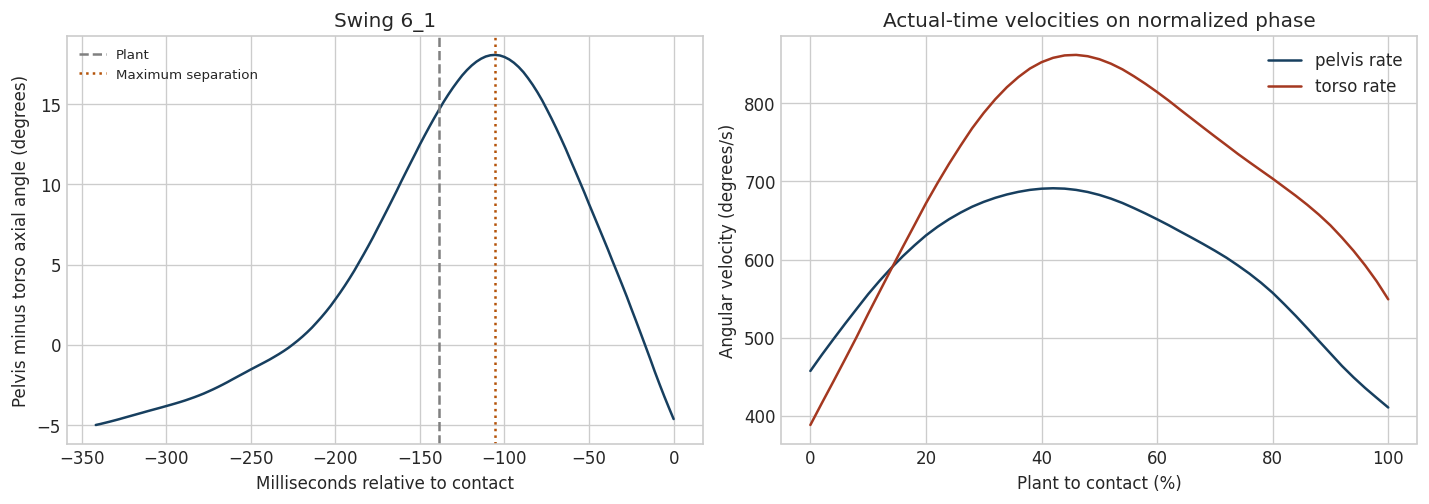

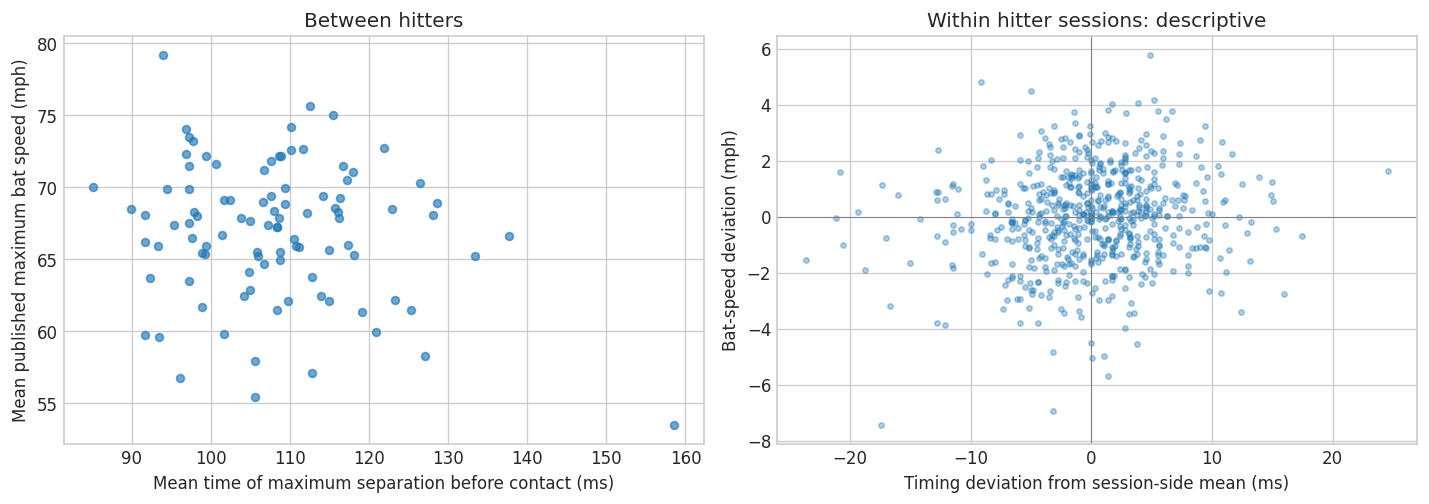

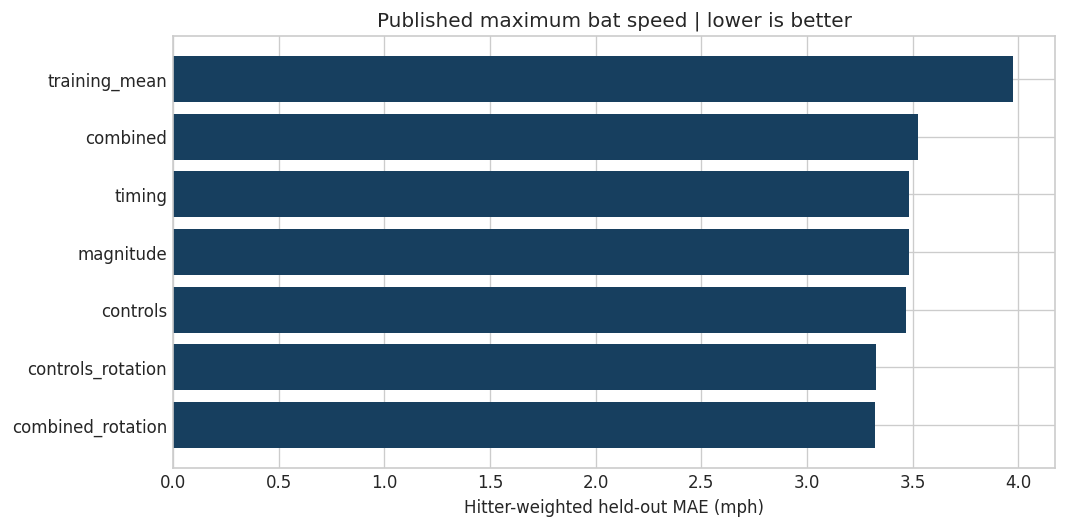

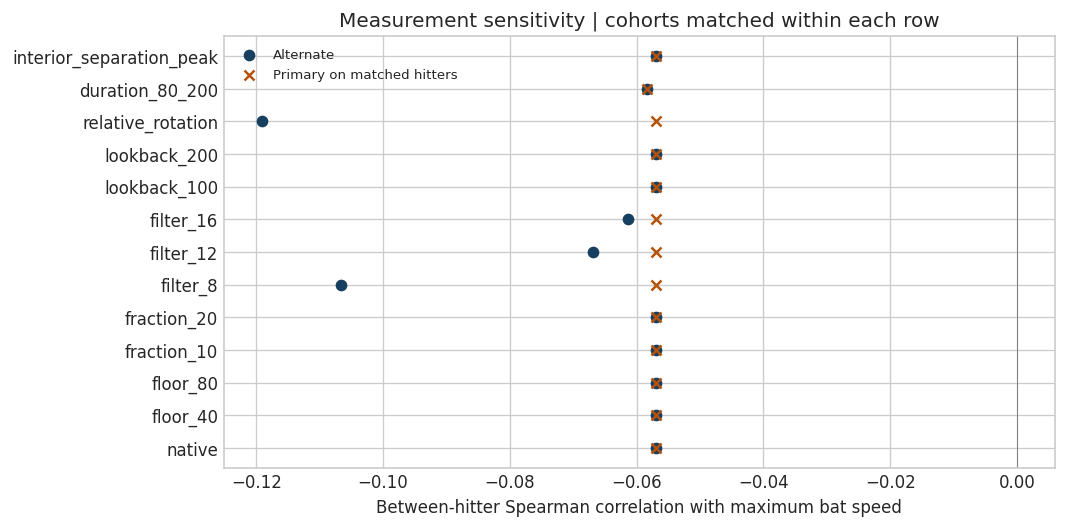

Adding separation magnitude and timing changed held-out MAE by -0.058 mph (positive favors added features; conditional hitter-bootstrap 95% interval -0.196 to +0.083).
A reliable improvement over body/bat controls is not established.
Saved measurements, audits, associations, grouped predictions, sensitivity comparisons, figures and study_summary.html.


In [7]:
selected = str(SELECTED_SWING) if SELECTED_SWING is not None else measurements.session_swing.iloc[0]
if selected not in traces:
    raise KeyError('Selected swing is not retained')
r = measurements.set_index('session_swing').loc[selected]
tr = traces[selected]
fig,ax = plt.subplots(1,2,figsize=(12,4.3))
ax[0].plot(tr['ms'],tr['full_separation'],color='#173f5f')
ax[0].axvline(1000*(r.plant_time-r.contact_time),color='gray',ls='--',label='Plant')
ax[0].axvline(-r.peak_separation_ms_before_contact,color='#b45309',ls=':',label='Maximum separation')
ax[0].set(xlabel='Milliseconds relative to contact',ylabel='Pelvis minus torso axial angle (degrees)',title='Swing '+selected)
ax[0].legend(fontsize=8)
for channel,color in [('pelvis_rate','#173f5f'),('torso_rate','#a43820')]:
    ax[1].plot(tr['pct'],tr[channel],color=color,label=channel.replace('_',' '))
ax[1].set(xlabel='Plant to contact (%)',ylabel='Angular velocity (degrees/s)',title='Actual-time velocities on normalized phase')
ax[1].legend()
fig.tight_layout()
fig.savefig(FIG/'selected_swing.png',dpi=160)
plt.show()
fig,axes = plt.subplots(1,2,figsize=(12,4.3))
feature = 'peak_separation_ms_before_contact'
target = TARGETS['peak_speed']
d = measurements.dropna(subset=[feature,target]).copy()
b = d.groupby('user')[[feature,target]].mean()
axes[0].scatter(b[feature],b[target],s=22,alpha=.65)
axes[0].set(xlabel='Mean time of maximum separation before contact (ms)',ylabel='Mean published maximum bat speed (mph)',title='Between hitters')
d = d[d.groupby(GROUP).session_swing.transform('size')>=3].copy()
z = d[[feature,target]]-d.groupby(GROUP)[[feature,target]].transform('mean')
axes[1].scatter(z[feature],z[target],s=10,alpha=.35)
axes[1].axhline(0,color='gray',lw=.6)
axes[1].axvline(0,color='gray',lw=.6)
axes[1].set(xlabel='Timing deviation from session-side mean (ms)',ylabel='Bat-speed deviation (mph)',title='Within hitter sessions: descriptive')
fig.tight_layout()
fig.savefig(FIG/'between_within_timing.png',dpi=160)
plt.show()
fig,ax = plt.subplots(figsize=(9,4.5))
m = model_summary[model_summary.outcome=='peak_speed'].sort_values('hitter_mae_mph')
ax.barh(m.model,m.hitter_mae_mph,color='#173f5f')
ax.set(xlabel='Hitter-weighted held-out MAE (mph)',title='Published maximum bat speed | lower is better')
fig.tight_layout()
fig.savefig(FIG/'grouped_model_comparison.png',dpi=160)
plt.show()
fig,ax = plt.subplots(figsize=(9,4.5))
s = sensitivity[sensitivity.feature==feature].dropna(subset=['alternate_speed_rho_matched'])
ax.scatter(s.alternate_speed_rho_matched,s.setting,color='#173f5f',label='Alternate')
ax.scatter(s.primary_speed_rho_matched,s.setting,color='#b45309',marker='x',label='Primary on matched hitters')
ax.axvline(0,color='gray',lw=.6)
ax.set(xlabel='Between-hitter Spearman correlation with maximum bat speed',title='Measurement sensitivity | cohorts matched within each row')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG/'timing_sensitivity.png',dpi=160)
plt.show()
manifest = {'study':20,'primary_separation':'signed pelvis minus torso processed axial angles',
    'association_controls':INFERENCE_CONTROLS,'association_bat_weight_omitted_reason':'only two hitters have nonstandard bat drop; one remains in Blast cohort, giving unit leverage under full controls',
    'primary_outcome':'published bat_speed_mph_max_x; exact maximum search window unverified',
    'c3d_required':False,'seed_repeats':list(SEEDS),'alphas':list(ALPHAS),'bootstraps':BOOTSTRAPS,
    'inputs':{p.name:sha256(p) for p in [RAW/(n+'.csv') for n in ('joint_angles','joint_velos','metadata','poi_metrics')]},
    'settings':settings,'models':MODELS,'raw_swings':len(base),'retained_swings':len(measurements),
    'python':platform.python_version(),'packages':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','statsmodels','matplotlib']}}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
c = comparisons[(comparisons.outcome=='peak_speed') & (comparisons.baseline=='controls') & (comparisons.added=='combined')].iloc[0]
message = f"Adding separation magnitude and timing changed held-out MAE by {c.mae_improvement_mph:+.3f} mph (positive favors added features; conditional hitter-bootstrap 95% interval {c.ci_low:+.3f} to {c.ci_high:+.3f})."
conclusion = 'The interval supports an improvement within this dataset.' if c.ci_low>0 else 'A reliable improvement over body/bat controls is not established.'
report = '<html><head><meta charset="utf-8"><title>Separation & Bat Speed</title><style>body{font:16px system-ui;max-width:1100px;margin:40px auto;padding:0 24px;color:#17232e}img{max-width:100%}table{display:block;overflow-x:auto;max-width:100%;border-collapse:collapse;font-size:13px}td,th{padding:7px;border-bottom:1px solid #ddd}</style></head><body>'
report += '<h1>Pelvis–Torso Separation & Bat Speed</h1><p>'+html.escape(message+' '+conclusion)+'</p>'
report += '<p>Primary separation is a signed axial-angle difference. It is not a direct measure of muscle stretch, stored energy, or causal force transfer. Maximum bat speed uses the published scalar; its exact search window is unverified. Within-session findings are associations, not individual intervention effects.</p>'
report += '<h2>Outcome cohorts</h2>'+pd.DataFrame(cohorts).to_html(index=False)
report += '<h2>Paired held-out comparisons</h2>'+comparisons.round(4).to_html(index=False)
report += '<p>Between-hitter association intervals adjust height, mass, bat length and side. Bat weight is omitted from these regressions because bat-drop variation is sparse; prediction models retain it. Duration-screen refits use their own cohort; compare models within a row.</p>'
report += '<h2>Primary associations</h2>'+associations[associations.outcome=='peak_speed'].round(4).to_html(index=False)
report += '<h2>Joint within-session associations</h2>'+joint_associations[joint_associations.outcome=='peak_speed'].round(4).to_html(index=False)
report += '<h2>Matched measurement sensitivities</h2>'+sensitivity.round(4).to_html(index=False)
report += '<h2>Matched sensitivity models</h2>'+pd.DataFrame(refit_comparisons).round(4).to_html(index=False)
import base64
for p in sorted(FIG.glob('*.png')):
    report += '<h2>'+html.escape(p.stem.replace('_',' ').title())+'</h2><img src="data:image/png;base64,'+base64.b64encode(p.read_bytes()).decode()+'">'
report += '<p>Grouped folds hold out entire hitters. Scaling and tuning use training folds only. Conditional intervals resample fixed held-out errors and omit model-refitting uncertainty. Sensitivity comparisons are exploratory. Short sessions, restricted populations, shared measurement systems, and unmeasured pitch context limit interpretation.</p></body></html>'
(OUT/'study_summary.html').write_text(report)
print(message)
print(conclusion)
print('Saved measurements, audits, associations, grouped predictions, sensitivity comparisons, figures and study_summary.html.')
display(HTML('<p><b>'+html.escape(message+' '+conclusion)+'</b></p>'))